In [1]:
# ---------- CELL 0: locate the project (same in every notebook) ----------
import os, sys
from pathlib import Path

def find_root(marker="PROJECT_ROOT.marker"):
    here = Path.cwd().resolve()                      # start where this notebook runs
    for folder in [here, *here.parents]:             # go UP one level at a time
        if (folder / marker).exists():
            return folder
    if "google.colab" in sys.modules:                # Colab: look inside Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        for pattern in (marker, f"*/{marker}", f"*/*/{marker}", f"*/*/*/{marker}"):
            hits = sorted(Path("/content/drive/MyDrive").glob(pattern))
            if hits:
                return hits[0].parent
    raise FileNotFoundError("PROJECT_ROOT.marker not found - finish Day 1 first.")

ROOT = find_root()
os.chdir(ROOT / "notebooks")
RAW, CLEAN = ROOT/"data"/"raw", ROOT/"data"/"clean"
FEATURES, MODEL_OUT = ROOT/"data"/"features", ROOT/"data"/"model_outputs"
SQL_EXPORTS, BI_READY = ROOT/"data"/"sql_exports", ROOT/"data"/"bi_ready"
MODELS, REPORTS, DOCS = ROOT/"models", ROOT/"reports", ROOT/"docs"
FIGURES = REPORTS/"figures"
sys.path.append(str(ROOT/"src"))
print("Project root:", ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/Internmo/netflix_churn_project


In [2]:
# ---------- CELL 1: load and inspect ----------
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

tickets  = pd.read_csv(CLEAN / "support_tickets.csv", parse_dates=["ticket_date"])
feedback = pd.read_csv(CLEAN / "customer_feedback.csv", parse_dates=["feedback_date"])
churn    = pd.read_csv(CLEAN / "churn_labels.csv")

print("tickets :", len(tickets), "rows,", tickets["ticket_description"].nunique(), "distinct descriptions")
print("feedback:", len(feedback), "rows,", feedback["feedback_text"].nunique(), "distinct comments")
feedback["feedback_text"].value_counts().head(5)

tickets : 6120 rows, 32 distinct descriptions
feedback: 5046 rows, 13 distinct comments


,count
feedback_text,
"Average experience overall, some months are better than others depending on new releases.",568
"It works fine most of the time, occasional buffering but nothing major to complain about.",529
The service is decent but the content library could use more variety in regional languages.,502
"Love the recommendation engine, it keeps suggesting shows I actually end up enjoying.",417
"Great value for the price, my whole family uses different profiles without any issues.",416


In [3]:
# ---------- CELL 2: feedback themes ----------
FEEDBACK_RULES = [                                   # (theme, regular expression), first match wins
    ("General experience",   r"average experience|works fine"),
    ("Customer support",     r"support"),
    ("Recommendations",      r"recommendation"),
    ("Price & value",        r"price|value for"),
    ("App stability",        r"crash"),
    ("Streaming quality",    r"buffer|streaming quality|video quality"),
    ("Content library",      r"content|library|shows|variety"),
]

def feedback_theme(text):
    lowered = str(text).lower()
    for theme, pattern in FEEDBACK_RULES:
        if re.search(pattern, lowered):
            return theme
    return "Other"

feedback["theme"] = feedback["feedback_text"].apply(feedback_theme)

# check every distinct comment and the theme it got (read this table!)
(feedback.groupby(["theme", "feedback_text"]).size().rename("rows").reset_index()
         .assign(feedback_text=lambda d: d["feedback_text"].str[:90]))

,theme,feedback_text,rows
0,App stability,The app keeps crashing on my device and I have...,298
1,Content library,"Not enough new content being added, feels like...",268
2,Content library,"Really happy with the content library, discove...",382
3,Content library,The service is decent but the content library ...,502
4,Customer support,Customer support resolved my issue quickly and...,390
5,Customer support,Customer support took too long to respond to m...,294
6,General experience,"Average experience overall, some months are be...",568
7,General experience,"It works fine most of the time, occasional buf...",529
8,Price & value,Cancelled my plan because the price increase w...,260
9,Price & value,"Great value for the price, my whole family use...",416


In [4]:
# ---------- CELL 3: sanity checks ----------
assert (feedback["theme"] != "Other").all(), "some comments matched no rule"
print(pd.crosstab(feedback["theme"], feedback["sentiment_from_rating"]))

sentiment_from_rating  Negative  Neutral  Positive
theme                                             
App stability               298        0         0
Content library             268      502       382
Customer support            294        0       390
General experience            0     1097         0
Price & value               260        0       416
Recommendations               0        0       417
Streaming quality           316        0       406


In [5]:
# ---------- CELL 4: feedback theme summary ----------
feedback = feedback.merge(churn[["customer_id", "churned"]], on="customer_id", how="left")

# one row per customer and theme, so a customer who commented twice is not counted twice in the churn rate
customer_theme = feedback.drop_duplicates(["customer_id", "theme"])

feedback_summary = (feedback.groupby("theme")
    .agg(comments=("feedback_id", "count"), avg_rating=("rating", "mean"),
         negative_share=("sentiment_from_rating", lambda s: (s == "Negative").mean()))
    .join(customer_theme.groupby("theme").agg(customers=("customer_id", "nunique"), churn_rate=("churned", "mean")))
    .round(3).sort_values("comments", ascending=False))
feedback_summary["churn_rate_pct"] = (100 * feedback_summary["churn_rate"]).round(1)
overall = 100 * churn["churned"].mean()
print(f"Overall churn rate: {overall:.1f}%")
feedback_summary.drop(columns="churn_rate")

Overall churn rate: 24.9%


,comments,avg_rating,negative_share,customers,churn_rate_pct
theme,,,,,
Content library,1152,3.149,0.233,1047,23.0
General experience,1097,3.000,0.000,1003,25.9
Streaming quality,722,3.148,0.438,689,25.0
Customer support,684,3.227,0.430,649,27.9
Price & value,676,3.362,0.385,633,24.3
Recommendations,417,4.451,0.000,405,22.0
App stability,298,1.473,1.000,292,33.2


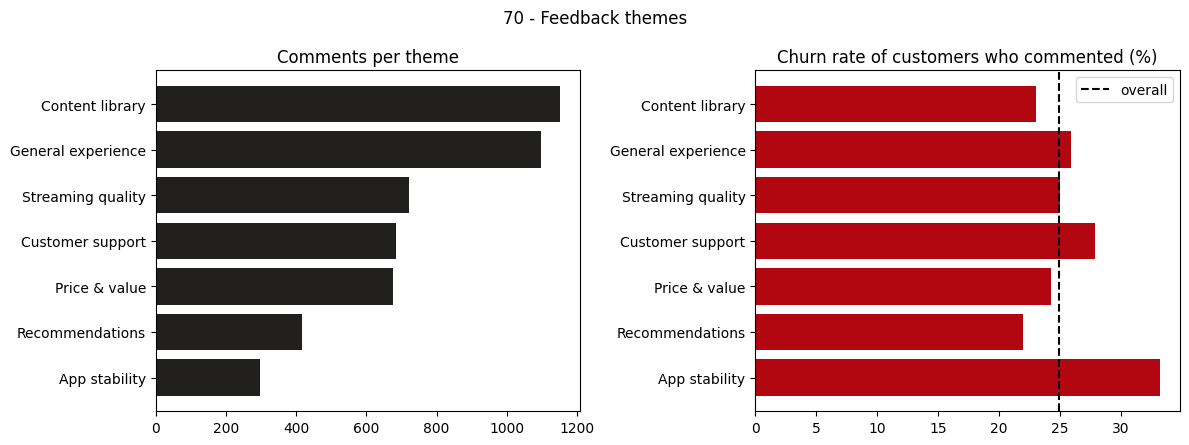

In [6]:
# ---------- CELL 5: chart ----------
order = feedback_summary.sort_values("comments")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(order.index, order["comments"], color="#221f1f"); axes[0].set_title("Comments per theme")
axes[1].barh(order.index, order["churn_rate_pct"], color="#b20710")
axes[1].axvline(overall, color="black", linestyle="--", label="overall"); axes[1].set_title("Churn rate of customers who commented (%)"); axes[1].legend()
fig.suptitle("70 - Feedback themes")
plt.tight_layout(); plt.savefig(FIGURES / "70_feedback_themes.png", bbox_inches="tight"); plt.show()

In [7]:
# ---------- CELL 6: top words per sentiment ----------
from sklearn.feature_extraction.text import TfidfVectorizer

def top_terms(texts, how_many=8):
    vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3)
    matrix = vectorizer.fit_transform(texts)
    scores = np.asarray(matrix.mean(axis=0)).ravel()
    terms = np.array(vectorizer.get_feature_names_out())
    return ", ".join(terms[scores.argsort()[::-1][:how_many]])

# the vocabulary is fitted on ALL comments, but we print the top words inside each sentiment group
for sentiment in ["Negative", "Neutral", "Positive"]:
    print(f"{sentiment:9s}:", top_terms(feedback.loc[feedback["sentiment_from_rating"] == sentiment, "feedback_text"]))

Negative : worth, content, watch, device able, watch days, keeps, crashing, keeps crashing
Neutral  : works fine, works, time occasional, time, buffering, buffering major, fine time, major
Positive : great, shows, faster update, quality excellent, quality, streaming quality, streaming, feels faster


In [8]:
# ---------- CELL 7: cluster the tickets ----------
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=5)
matrix = vectorizer.fit_transform(tickets["ticket_description"])
terms = np.array(vectorizer.get_feature_names_out())

K_TEXT = tickets["issue_category"].nunique()              # 6 human categories, so we ask for 6 clusters
km = KMeans(n_clusters=K_TEXT, n_init=10, random_state=42).fit(matrix)
tickets["text_cluster"] = km.labels_

agreement = adjusted_rand_score(tickets["issue_category"], tickets["text_cluster"])
print(f"Agreement between text clusters and human categories (ARI): {agreement:.2f}   (1 = identical, 0 = unrelated)")

# top words of each cluster
centroids = km.cluster_centers_
for c in range(K_TEXT):
    print(f"cluster {c}:", ", ".join(terms[centroids[c].argsort()[::-1][:6]]))

Agreement between text clusters and human categories (ARI): 0.26   (1 = identical, 0 = unrelated)
cluster 0: month, charge, refund, send, send detailed, detailed invoice
cluster 1: new, login, multiple login, multiple, account got, got locked
cluster 2: time, time try, mobile, mobile device, reinstalled twice, reinstalled
cluster 3: watch, sync, title try, try watch, tablet, sync video
cluster 4: email, password, times, address, address account, arrived
cluster 5: plan, video quality, quality, video, premium, premium plan


In [9]:
# ---------- CELL 8: cluster names ----------
cross = pd.crosstab(tickets["text_cluster"], tickets["issue_category"])
names = {}
for cluster, row in cross.iterrows():
    main = row.idxmax()
    share = row.max() / row.sum()
    names[cluster] = f"{main}"
    print(f"cluster {cluster} -> {main:20s} ({100 * share:.0f}% of its tickets)")

# two clusters can end up with the same dominant category; make names unique
seen = {}
for cluster in sorted(names):
    seen[names[cluster]] = seen.get(names[cluster], 0) + 1
    if list(names.values()).count(names[cluster]) > 1:
        names[cluster] = f"{names[cluster]} (type {seen[names[cluster]]})"
tickets["text_theme"] = tickets["text_cluster"].map(names)
cross

cluster 0 -> Billing & Payments   (80% of its tickets)
cluster 1 -> Account Access       (66% of its tickets)
cluster 2 -> Device & App         (54% of its tickets)
cluster 3 -> Streaming Quality    (53% of its tickets)
cluster 4 -> Account Access       (85% of its tickets)
cluster 5 -> Billing & Payments   (31% of its tickets)


issue_category,Account Access,Billing & Payments,Content,Device & App,Streaming Quality,Subscription
text_cluster,,,,,,
0,0,860,0,0,0,213
1,384,0,0,201,0,0
2,0,0,0,384,332,0
3,0,0,145,153,336,0
4,614,110,0,0,0,0
5,0,739,326,0,655,668


                    tickets  avg_resolution_hours  avg_csat  customers  churn_rate_pct
issue_category                                                                        
Billing & Payments     1709                 17.30      2.98       1570            27.0
Streaming Quality      1323                 18.57      3.04       1221            26.0
Account Access          998                 17.78      3.47        938            25.0
Subscription            881                 18.24      3.50        839            26.0
Device & App            738                 18.40      3.56        697            26.0
Content                 471                 18.35      3.55        456            27.0


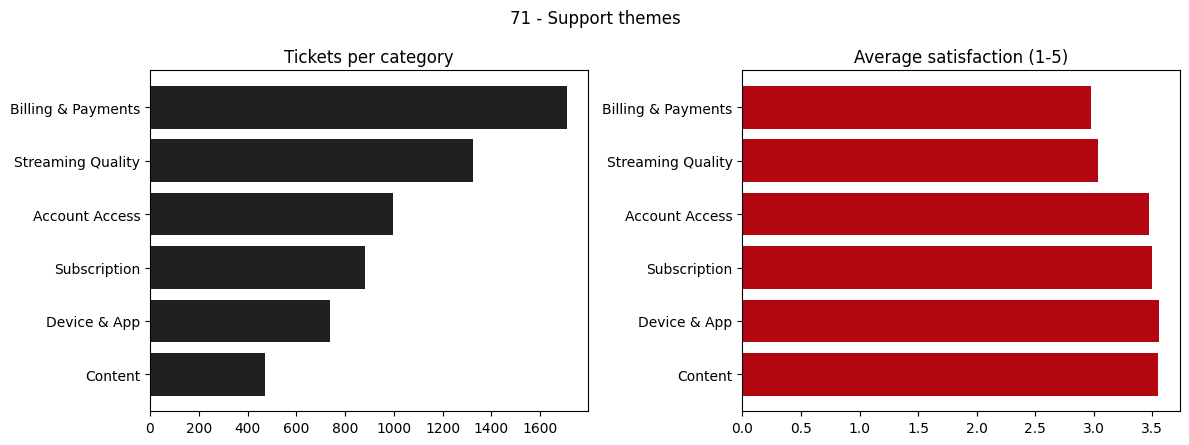

In [10]:
# ---------- CELL 9: ticket theme summary ----------
tickets = tickets.merge(churn[["customer_id", "churned"]], on="customer_id", how="left")

ticket_summary = (tickets.groupby("issue_category")
    .agg(tickets=("ticket_id", "count"), avg_resolution_hours=("resolution_time_hours", "mean"),
         avg_csat=("customer_satisfaction_score", "mean"))
    .join(tickets.drop_duplicates(["customer_id", "issue_category"]).groupby("issue_category")
          .agg(customers=("customer_id", "nunique"), churn_rate=("churned", "mean")))
    .round(2))
ticket_summary["churn_rate_pct"] = (100 * ticket_summary["churn_rate"]).round(1)
ticket_summary = ticket_summary.sort_values("tickets", ascending=False)
print(ticket_summary.drop(columns="churn_rate").to_string())

order = ticket_summary.sort_values("tickets")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(order.index, order["tickets"], color="#221f1f"); axes[0].set_title("Tickets per category")
axes[1].barh(order.index, order["avg_csat"], color="#b20710"); axes[1].set_title("Average satisfaction (1-5)")
fig.suptitle("71 - Support themes")
plt.tight_layout(); plt.savefig(FIGURES / "71_ticket_themes.png", bbox_inches="tight"); plt.show()

In [11]:
# ---------- CELL 10: save text outputs ----------
MODEL_OUT.mkdir(parents=True, exist_ok=True)
feedback[["feedback_id", "customer_id", "feedback_date", "rating", "sentiment_label", "sentiment_from_rating", "theme"]] \
    .to_csv(MODEL_OUT / "text_themes_feedback.csv", index=False, date_format="%Y-%m-%d")
tickets[["ticket_id", "customer_id", "ticket_date", "issue_category", "issue_subcategory", "text_cluster", "text_theme"]] \
    .to_csv(MODEL_OUT / "text_themes_tickets.csv", index=False, date_format="%Y-%m-%d")

summary = pd.concat([
    feedback_summary.reset_index().assign(source="feedback", theme_name=lambda d: d["theme"])
        [["source", "theme_name", "comments", "customers", "avg_rating", "negative_share", "churn_rate_pct"]]
        .rename(columns={"comments": "items"}),
    ticket_summary.reset_index().assign(source="tickets", theme_name=lambda d: d["issue_category"])
        [["source", "theme_name", "tickets", "customers", "avg_csat", "avg_resolution_hours", "churn_rate_pct"]]
        .rename(columns={"tickets": "items"}),
], ignore_index=True)
summary.to_csv(MODEL_OUT / "text_theme_summary.csv", index=False)
print("text outputs saved:", len(feedback), "feedback rows,", len(tickets), "tickets")

text outputs saved: 5046 feedback rows, 6120 tickets


In [12]:
# ---------- CELL 11: load for the BI package ----------
BI_READY.mkdir(parents=True, exist_ok=True)
AS_OF = pd.Timestamp((CLEAN / "as_of_date.txt").read_text().strip())

customers     = pd.read_csv(CLEAN / "customers.csv", parse_dates=["registration_date"])
plans         = pd.read_csv(CLEAN / "subscription_plans.csv")
subscriptions = pd.read_csv(CLEAN / "subscriptions.csv", parse_dates=["subscription_start_date", "subscription_end_date", "cancellation_date"])
content       = pd.read_csv(CLEAN / "content.csv")
viewing       = pd.read_csv(CLEAN / "viewing_activity.csv", parse_dates=["viewing_date"])
payments      = pd.read_csv(CLEAN / "payments.csv", parse_dates=["payment_date"])
churn_full    = pd.read_csv(CLEAN / "churn_labels.csv", parse_dates=["churn_date"])

def save_bi(df, name):
    """Write a table into data/bi_ready as CSV (dates as YYYY-MM-DD, blanks stay blank)."""
    df.to_csv(BI_READY / f"{name}.csv", index=False, date_format="%Y-%m-%d")
    print(f"saved {name + '.csv':32s} rows={len(df):>8,} columns={df.shape[1]}")

In [13]:
# ---------- CELL 12: dim_customer ----------
current = (subscriptions[subscriptions["subscription_end_date"].isna()]
           .merge(plans[["plan_id", "plan_name", "monthly_price"]].rename(columns={"monthly_price": "plan_list_price"}), on="plan_id")
           [["customer_id", "plan_id", "plan_name", "plan_list_price", "monthly_price", "auto_renew", "subscription_status"]]
           .rename(columns={"monthly_price": "billed_monthly_price"}))

dim_customer = (customers.drop(columns=["state_or_region"])
                .merge(churn_full, on="customer_id", how="left")
                .merge(current, on="customer_id", how="left"))

dim_customer["age_band"] = pd.cut(dim_customer["age"], [0, 24, 34, 44, 54, 64, 120],
                                  labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]).astype(str)
dim_customer["tenure_years"] = ((AS_OF - dim_customer["registration_date"]).dt.days / 365.25).round(2)
dim_customer["customer_status"] = np.where(dim_customer["churned"] == 1, "Churned", "Active")

# model results exist only for customers who are active on the as-of date (blank for churned customers)
risk     = pd.read_csv(MODEL_OUT / "churn_predictions.csv")[["customer_id", "churn_probability", "risk_tier", "risk_percentile", "risk_flags", "flag_count"]]
segment  = pd.read_csv(MODEL_OUT / "customer_segments.csv")[["customer_id", "segment_name"]]
value    = pd.read_csv(MODEL_OUT / "customer_value.csv")[["customer_id", "expected_value_12m", "value_at_risk_12m"]]
health   = pd.read_csv(SQL_EXPORTS / "q37_customer_health_score.csv")[["customer_id", "risk_score_0_100", "health_score_0_100"]] \
             .rename(columns={"risk_score_0_100": "sql_risk_score", "health_score_0_100": "sql_health_score"})

for extra in [risk, segment, value, health]:
    dim_customer = dim_customer.merge(extra, on="customer_id", how="left")

# checks
assert dim_customer["customer_id"].is_unique and len(dim_customer) == 8000
assert dim_customer["plan_name"].notna().all()
assert dim_customer.loc[dim_customer["customer_status"] == "Active", ["churn_probability", "risk_tier"]].notna().all().all()
assert dim_customer.loc[dim_customer["customer_status"] == "Churned", "churn_probability"].isna().all()
save_bi(dim_customer, "dim_customer")

saved dim_customer.csv                 rows=   8,000 columns=33


In [14]:
# ---------- CELL 13: dim_date, dim_plan, dim_content ----------
first_day = min(customers["registration_date"].min(), payments["payment_date"].min()).normalize()
calendar = pd.DataFrame({"date": pd.date_range(first_day, AS_OF.normalize() + pd.offsets.MonthEnd(0))})
calendar["year"]            = calendar["date"].dt.year
calendar["quarter"]         = "Q" + calendar["date"].dt.quarter.astype(str)
calendar["year_quarter"]    = calendar["year"].astype(str) + "-" + calendar["quarter"]
calendar["month_number"]    = calendar["date"].dt.month
calendar["month_name"]      = calendar["date"].dt.strftime("%b")
calendar["year_month"]      = calendar["date"].dt.strftime("%Y-%m")
calendar["month_start"]     = calendar["date"].dt.to_period("M").dt.start_time
calendar["week_start"]      = (calendar["date"] - pd.to_timedelta(calendar["date"].dt.weekday, unit="D"))
calendar["day_name"]        = calendar["date"].dt.day_name()
calendar["is_weekend"]      = (calendar["date"].dt.weekday >= 5).astype(int)
calendar["is_after_as_of"]  = (calendar["date"] > AS_OF).astype(int)
save_bi(calendar, "dim_date")

save_bi(plans, "dim_plan")
save_bi(content, "dim_content")

saved dim_date.csv                     rows=   2,738 columns=12
saved dim_plan.csv                     rows=       3 columns=6
saved dim_content.csv                  rows=     500 columns=9


In [15]:
# ---------- CELL 14: fact tables ----------
save_bi(payments[["payment_id", "customer_id", "subscription_id", "payment_date", "amount", "payment_status",
                  "payment_method", "failed_payment_reason", "amount_flag"]], "fact_payments")

save_bi(viewing, "fact_viewing")

save_bi(tickets[["ticket_id", "customer_id", "ticket_date", "issue_category", "issue_subcategory", "priority",
                 "ticket_status", "resolution_time_hours", "customer_satisfaction_score", "text_theme"]], "fact_tickets")

save_bi(feedback[["feedback_id", "customer_id", "feedback_date", "rating", "sentiment_label",
                  "sentiment_from_rating", "sentiment_mismatch", "theme"]].rename(columns={"theme": "feedback_theme"}), "fact_feedback")

save_bi(subscriptions, "fact_subscriptions")

saved fact_payments.csv                rows= 110,735 columns=9
saved fact_viewing.csv                 rows=  66,422 columns=9
saved fact_tickets.csv                 rows=   6,120 columns=10
saved fact_feedback.csv                rows=   5,046 columns=8
saved fact_subscriptions.csv           rows=   8,875 columns=10


In [16]:
# ---------- CELL 15: one-row KPI table ----------
metrics = pd.read_csv(REPORTS / "churn_model_metrics.csv")
test_auc = metrics.loc[metrics["stage"] == "locked test set (AUC)", "auc"].iloc[0]

active_customers = dim_customer[dim_customer["customer_status"] == "Active"]
last_year_payments = payments[(payments["payment_status"] == "Success") &
                              (payments["payment_date"] > payments["payment_date"].max() - pd.DateOffset(months=12))]
kpi = pd.DataFrame([{
    "as_of_date":               AS_OF.date(),
    "total_customers":          len(dim_customer),
    "active_customers":         len(active_customers),
    "churned_customers":        int((dim_customer["churned"] == 1).sum()),
    "churn_rate_pct":           round(100 * dim_customer["churned"].mean(), 2),
    "monthly_recurring_revenue": round(active_customers["billed_monthly_price"].sum(), 2),
    "revenue_last_12m_payments": round(last_year_payments["amount"].sum(), 2),
    "high_risk_customers":      int((dim_customer["risk_tier"] == "High").sum()),
    "value_at_risk_12m":        round(active_customers["value_at_risk_12m"].sum(), 2),
    "churn_model_test_auc":     test_auc,
}])
save_bi(kpi, "kpi_summary")
kpi.T

saved kpi_summary.csv                  rows=       1 columns=10


,0
as_of_date,2026-06-30
total_customers,8000
active_customers,6009
churned_customers,1991
churn_rate_pct,24.89
monthly_recurring_revenue,81364.91
revenue_last_12m_payments,205409.27
high_risk_customers,1201
value_at_risk_12m,151334.89
churn_model_test_auc,0.568


In [17]:
# ---------- CELL 16: model_* and sql_* tables ----------
import shutil

model_tables = {                                   # source in data/model_outputs  ->  name in data/bi_ready
    "segment_profile.csv":     "model_segment_profile.csv",
    "campaign_scenarios.csv":  "model_campaign_scenarios.csv",
    "text_theme_summary.csv":  "model_text_theme_summary.csv",
}
for source, target in model_tables.items():
    shutil.copy(MODEL_OUT / source, BI_READY / target)
    print("copied", target)

# lift table from the test set (Day 10 / 12), so the dashboard can show model quality
test_pred = pd.read_csv(MODEL_OUT / "churn_test_predictions.csv")
test_pred["risk_decile"] = pd.qcut(test_pred["churn_probability"].rank(method="first"), 10, labels=range(1, 11)).astype(int)
lift = (test_pred.groupby("risk_decile").agg(customers=("churned", "size"), actual_churn_rate=("churned", "mean"),
                                              avg_predicted=("churn_probability", "mean")).round(4).reset_index())
lift["lift_vs_average"] = (lift["actual_churn_rate"] / test_pred["churned"].mean()).round(3)
save_bi(lift, "model_lift_by_decile")

sql_tables = {                                     # SQL exports from Days 5-7  ->  name in data/bi_ready
    "q20_cohort_retention.csv":     "sql_cohort_retention.csv",
    "q30_country_churn_summary.csv": "sql_country_churn_summary.csv",
    "q33_winback_candidates.csv":   "sql_winback_candidates.csv",
    "q34_plan_migration.csv":       "sql_plan_migration.csv",
    "q35_wau_mau.csv":              "sql_wau_mau.csv",
    "q36_outreach_list.csv":        "sql_outreach_list.csv",
}
for source, target in sql_tables.items():
    shutil.copy(SQL_EXPORTS / source, BI_READY / target)
    print("copied", target)

copied model_segment_profile.csv
copied model_campaign_scenarios.csv
copied model_text_theme_summary.csv
saved model_lift_by_decile.csv         rows=      10 columns=5
copied sql_cohort_retention.csv
copied sql_country_churn_summary.csv
copied sql_winback_candidates.csv
copied sql_plan_migration.csv
copied sql_wau_mau.csv
copied sql_outreach_list.csv


In [18]:
# ---------- CELL 17: integrity checks ----------
tables = {path.stem: pd.read_csv(path) for path in sorted(BI_READY.glob("*.csv"))}
print(len(tables), "tables:", ", ".join(tables))

ids = set(tables["dim_customer"]["customer_id"])
for fact in ["fact_payments", "fact_viewing", "fact_tickets", "fact_feedback", "fact_subscriptions"]:
    missing = (~tables[fact]["customer_id"].isin(ids)).sum()
    assert missing == 0, f"{fact} has {missing} rows with an unknown customer"
assert tables["fact_viewing"]["content_id"].isin(tables["dim_content"]["content_id"]).all()
assert tables["fact_subscriptions"]["plan_id"].isin(tables["dim_plan"]["plan_id"]).all()
for fact, key in [("fact_payments", "payment_id"), ("fact_viewing", "viewing_id"), ("fact_tickets", "ticket_id"),
                  ("fact_feedback", "feedback_id"), ("fact_subscriptions", "subscription_id")]:
    assert tables[fact][key].is_unique, f"{fact}.{key} is not unique"

# the dashboard KPIs must equal what we computed elsewhere
assert tables["kpi_summary"].loc[0, "total_customers"] == 8000
assert abs(tables["kpi_summary"].loc[0, "churn_rate_pct"] - 24.89) < 0.01      # same as SQL Q3
print("All Day 13 checks passed.")

20 tables: dim_content, dim_customer, dim_date, dim_plan, fact_feedback, fact_payments, fact_subscriptions, fact_tickets, fact_viewing, kpi_summary, model_campaign_scenarios, model_lift_by_decile, model_segment_profile, model_text_theme_summary, sql_cohort_retention, sql_country_churn_summary, sql_outreach_list, sql_plan_migration, sql_wau_mau, sql_winback_candidates
All Day 13 checks passed.


In [19]:
# ---------- CELL 18: data dictionary and relationships ----------
dictionary = pd.DataFrame([{"table": name, "column": col, "type": str(df[col].dtype), "blank_values": int(df[col].isna().sum()),
                            "distinct_values": int(df[col].nunique())}
                           for name, df in tables.items() for col in df.columns])
dictionary.to_csv(DOCS / "bi_data_dictionary.csv", index=False)

relationships = pd.DataFrame([
    ("dim_customer", "customer_id", "fact_payments",      "customer_id",  "one-to-many"),
    ("dim_customer", "customer_id", "fact_viewing",       "customer_id",  "one-to-many"),
    ("dim_customer", "customer_id", "fact_tickets",       "customer_id",  "one-to-many"),
    ("dim_customer", "customer_id", "fact_feedback",      "customer_id",  "one-to-many"),
    ("dim_customer", "customer_id", "fact_subscriptions", "customer_id",  "one-to-many"),
    ("dim_content",  "content_id",  "fact_viewing",       "content_id",   "one-to-many"),
    ("dim_plan",     "plan_id",     "fact_subscriptions", "plan_id",      "one-to-many"),
    ("dim_date",     "date",        "fact_payments",      "payment_date", "one-to-many (active)"),
    ("dim_date",     "date",        "fact_viewing",       "viewing_date", "one-to-many (active)"),
    ("dim_date",     "date",        "fact_tickets",       "ticket_date",  "one-to-many (active)"),
    ("dim_date",     "date",        "fact_feedback",      "feedback_date", "one-to-many (active)"),
], columns=["from_table", "from_column", "to_table", "to_column", "type"])
relationships.to_csv(DOCS / "bi_relationships.csv", index=False)
print("documented", dictionary["table"].nunique(), "tables and", len(relationships), "relationships")

with open(DOCS / "project_log.md", "a") as f:
    f.write(f"""## Day 13 - Text themes and BI package
- Feedback themes by keyword rules (7 themes); ticket themes by TF-IDF + K-Means, agreement with human categories ARI {agreement:.2f}.
- NOTE: text is templated (32 ticket descriptions, 13 feedback comments), so results are cleaner than real text would be.
- data/bi_ready now holds {len(tables)} CSV tables (star schema + model_ and sql_ tables). Integrity checks passed.
- docs/bi_data_dictionary.csv and docs/bi_relationships.csv describe the package.

""")

documented 20 tables and 11 relationships
